# All exo cameras: more views per take

So far every exo result used one camera per take (`best_exo`). Each take has 4-6 exo cameras, and more training takes
helped every probe, so the other cameras are a cheap way to get more (correlated) training data. Frozen TimeSformer
K600, squash, 8 FPS, 1 s clips, L12 token std averaged over clips, for every exo camera of all 2,111 official takes
(`timesformer_allexo_extract.py`, pooled into `embeddings/ts_tokenstd_allviews.pt`).

Exo variants (each also concatenated with ego):
- **best**: the `best_exo` camera only (the baseline so far)
- **all-cam mean**: the token-std vector averaged over cameras (feature-level fusion, one row per take)
- **multi-cam rows**: every camera is a training row (weight 1/n_cameras, so each take counts once); a take's
  prediction is the mean over its cameras. Also scored using the best camera's row alone, to separate the training
  augmentation from the test-time averaging.

Because one take's camera rows are near-duplicates, the ridge / logistic penalty is chosen by an inner GroupKFold over
participants (not leave-one-out), for **every** method here, including the one-row ones, so they are comparable.

Part A: commentary takes (1,338), 4 x 5-fold StratifiedGroupKFold by participant, level and expert-rating targets,
same scoring as `expert_rating.ipynb`. Part B: the official split (train 1,655 -> val 456), accuracy and Spearman.

In [1]:
import ast
import json
from collections import Counter, defaultdict
from pathlib import Path

import av
import numpy as np

# Same takes as the earlier idea_1 notebooks: video and transcribed expert commentary, train / SkillFormer test split.
DATA_ROOT = next(
    p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir()
)
ANNOTATION_ROOT = DATA_ROOT / "annotations"
COMMENTARY_ROOT = ANNOTATION_ROOT / "expert_commentary"
WINDOW_FPS = 1

LEVELS = {
    "Novice": 1,
    "Early Expert": 2,
    "Intermediate Expert": 3,
    "Late Expert": 4,
}

def take_name(m):
    return m["video_paths"]["ego"].split("/")[1]

def video_path(m):
    parts = m["video_paths"]["ego"].split("/")
    parts[-1:-1] = ["downscaled", "448"]
    return DATA_ROOT.joinpath(*parts)

def has_commentary(take):
    """Whether any expert recorded transcribed commentary on the take (the take set of the earlier notebooks)."""
    for data_path in (COMMENTARY_ROOT / take).rglob("data.json"):
        transcript_path = data_path.parent / "transcriptions.json"
        if not transcript_path.exists():
            continue
        data = json.loads(data_path.read_text(encoding="utf-8"))
        transcripts = json.loads(transcript_path.read_text(encoding="utf-8"))
        if any(transcripts.get(a.get("recording_path"), {}).get("text", "").strip() for a in data.get("annotations", [])):
            return True
    return False

def num_seconds(path):
    """Number of 1 FPS frames decode_1fps() gets from the video (frames 0, 30, 60, ... at 30 FPS)."""
    with av.open(str(path)) as container:
        stream = container.streams.video[0]
        step = round(float(stream.average_rate) / WINDOW_FPS)
        return (stream.frames - 1) // step + 1

with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as file:
    test_takes = {json.loads(line)["video_paths"][0].split("/")[1] for line in file}

def split_clips(split):
    annotation_file = "proficiency_demonstrator_train.json" if split == "train" else "proficiency_demonstrator_val.json"
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        metadata = json.load(file)["annotations"]
    clips = []
    for m in metadata:
        if split == "test" and take_name(m) not in test_takes:
            continue
        if not video_path(m).exists() or not has_commentary(take_name(m)):
            continue
        clips.append({"take_name": take_name(m), "scenario": m["scenario_name"], "score": LEVELS[m["proficiency_score"]],
                      "participant": m["origin_participant_id"], "video": str(video_path(m)),
                      "seconds": num_seconds(video_path(m))})
    return clips

clips_by_split = {split: split_clips(split) for split in ("train", "test")}
clips = clips_by_split["test"]
clip_of = {clip["take_name"]: clip for split_list in clips_by_split.values() for clip in split_list}
for split, split_list in clips_by_split.items():
    print(f"{split}: {len(split_list)} takes, {sum(c['seconds'] for c in split_list) / 3600:.1f} h of video")

# Good executions (polarity 1) and tips for improvement (polarity 0) of those takes. Each entry's "list" is a Python
# list literal of sentences (NaN for a few blank entries, which are dropped).
POLARITIES = {"good_executions": (1, "Good execution"), "tips_for_improvement": (0, "Tip for improvement")}

def entry_sentences(entry):
    if not isinstance(entry.get("list"), str):
        return []
    try:
        items = ast.literal_eval(entry["list"])
    except (ValueError, SyntaxError):
        items = [entry["list"]]
    return [s.strip() for s in (items if isinstance(items, list) else [items]) if isinstance(s, str) and s.strip()]

demonstration = {}
for annotation_file in ("proficiency_demonstration_train.json", "proficiency_demonstration_val.json"):
    with open(ANNOTATION_ROOT / annotation_file, encoding="utf-8") as file:
        demonstration.update({take_name(m): m for m in json.load(file)["annotations"]})

moments = []
for split, split_list in clips_by_split.items():
    for clip in split_list:
        m = demonstration.get(clip["take_name"])
        for key, (polarity, tag) in POLARITIES.items():
            for entry in (m or {}).get(key, []):
                sentences = entry_sentences(entry)
                if sentences:
                    moments.append({"split": split, "take_name": clip["take_name"], "scenario": clip["scenario"],
                                    "polarity": polarity, "time": float(entry["video_time"]), "expert": entry["expert_uid"],
                                    "text": f"{tag}: {' '.join(sentences)}"})
covered = {m["take_name"] for m in moments}
for split in ("train", "test"):
    split_moments = [m for m in moments if m["split"] == split]
    print(f"{split}: {sum(c['take_name'] in covered for c in clips_by_split[split])} takes with moments, "
          f"{sum(m['polarity'] for m in split_moments)} good executions, {sum(1 - m['polarity'] for m in split_moments)} tips; "
          f"scenarios {dict(Counter(m['scenario'] for m in split_moments))}")

train: 1174 takes, 36.3 h of video
test: 164 takes, 4.9 h of video
train: 371 takes with moments, 8241 good executions, 8326 tips; scenarios {'Cooking': 5033, 'Basketball': 7358, 'Dance': 1841, 'Music': 2228, 'Soccer': 107}
test: 61 takes with moments, 1315 good executions, 1161 tips; scenarios {'Basketball': 1315, 'Cooking': 481, 'Music': 264, 'Dance': 416}


In [2]:
import pandas as pd
import torch
from scipy.stats import spearmanr

all_clips = clips_by_split["train"] + clips_by_split["test"]
names = [c["take_name"] for c in all_clips]
index_of = {t: i for i, t in enumerate(names)}
scores = np.array([c["score"] for c in all_clips])
scenarios = np.array([c["scenario"] for c in all_clips])
participants = np.array([c["participant"] for c in all_clips])
SCENARIO_NAMES = np.unique(scenarios)
log_duration = np.log([c["seconds"] for c in all_clips])

rows = []
for t in names:
    for path in sorted((COMMENTARY_ROOT / t).glob("*/data.json")):
        d = json.loads(path.read_text(encoding="utf-8"))
        prof = d.get("proficiency") or {}
        try:
            rating = float(prof.get("rating"))
        except (TypeError, ValueError):
            rating = np.nan
        why = (prof.get("why") or "").strip()
        if why or not np.isnan(rating):
            rows.append({"take_name": t, "expert": d.get("user_id") or path.parent.name, "rating": rating, "why": why})
R = pd.DataFrame(rows)
R["scenario"] = R.take_name.map(lambda t: clip_of[t]["scenario"])
stats = R.groupby("expert").rating.agg(["mean", "std"])
R["rating_z"] = (R.rating - R.expert.map(stats["mean"])) / R.expert.map(stats["std"]).replace(0, np.nan)
take_rating = R.groupby("take_name").rating.mean().reindex(names).to_numpy()
take_z = R.groupby("take_name").rating_z.mean().reindex(names).to_numpy()
print(f"{len(R)} expert entries over {R.take_name.nunique()} takes, {R.expert.nunique()} experts; "
      f"{R.rating.notna().sum()} ratings, {(R.why != '').sum()} whys; takes without a rating: {np.isnan(take_rating).sum()}")
print("ratings:", R.rating.value_counts().sort_index().to_dict())

def within_scenario(x, scen):
    x = np.asarray(x, float).copy()
    for s in np.unique(scen):
        m = scen == s
        x[m] -= np.nanmean(x[m])
    return x

# Held-out-expert rows: (take, expert i) with >= 2 rated experts; target = mean of the other experts.
held_rows = []
for t, grp in R[R.rating.notna()].groupby("take_name"):
    if len(grp) < 2:
        continue
    for i in range(len(grp)):
        others = grp.drop(grp.index[i])
        held_rows.append({"take_name": t, "i": index_of[t], "expert": grp.expert.iloc[i], "one": grp.rating.iloc[i],
                          "one_z": grp.rating_z.iloc[i], "others": others.rating.mean(), "others_z": others.rating_z.mean()})
H = pd.DataFrame(held_rows)
H["scenario"] = scenarios[H.i]
H_scen = H.scenario.to_numpy()
for col in ("one", "one_z", "others", "others_z"):
    H[col + "_c"] = within_scenario(H[col], H_scen)
print(f"{len(H)} held-out-expert rows over {H.take_name.nunique()} takes")
print(f"human: one expert vs others, raw {spearmanr(H.one_c, H.others_c)[0]:.3f}, z-scored {spearmanr(H.one_z_c, H.others_z_c)[0]:.3f}")

5004 expert entries over 1338 takes, 38 experts; 4910 ratings, 5004 whys; takes without a rating: 0
ratings: {1.0: 423, 2.0: 462, 3.0: 499, 4.0: 492, 5.0: 501, 6.0: 483, 7.0: 624, 8.0: 573, 9.0: 479, 10.0: 374}


4879 held-out-expert rows over 1307 takes
human: one expert vs others, raw 0.698, z-scored 0.767


#### Features

In [3]:
pv = torch.load(Path("embeddings") / "ts_tokenstd_allviews.pt", weights_only=False)

def view_tables(take_names):
    tn = list(take_names)
    cams = [pv["exo_all"][t] for t in tn]
    rows_take = np.concatenate([[i] * len(c) for i, c in enumerate(cams)])
    rows_cam = np.concatenate([list(c) for c in cams])
    is_best = np.array([pv["best_cam"][tn[i]] == cam for i, cam in zip(rows_take, rows_cam)])
    return {
        "ego": np.stack([pv["ego"][t] for t in tn]),
        "best": np.stack([pv["exo_best"][t] for t in tn]),
        "allmean": np.stack([np.mean(list(c.values()), 0) for c in cams]),
        "cams": np.vstack([np.stack(list(c.values())) for c in cams]),
    }, rows_take, is_best

SRC, ROW_TAKE, ROW_BEST = view_tables(names)
n_cams = np.bincount(ROW_TAKE)
print(f"{len(names)} takes, {len(ROW_TAKE)} exo camera rows; cameras per take {dict(zip(*np.unique(n_cams, return_counts=True)))}; "
      f"takes whose best_exo row is among them: {np.bincount(ROW_TAKE, ROW_BEST).astype(bool).sum()}")
# how different are the cameras? cosine of each camera to its take's best camera vs to other takes' best
from numpy.linalg import norm
cn = SRC["cams"] / norm(SRC["cams"], axis=1, keepdims=True)
bn = SRC["best"] / norm(SRC["best"], axis=1, keepdims=True)
same = (cn * bn[ROW_TAKE]).sum(1)[~ROW_BEST]
other = (cn * bn[np.random.default_rng(0).permutation(ROW_TAKE)]).sum(1)[~ROW_BEST]
print(f"cosine to the take's best camera: same take {np.median(same):.3f}, random other take {np.median(other):.3f}")

1338 takes, 5882 exo camera rows; cameras per take {np.int64(4): np.int64(867), np.int64(5): np.int64(412), np.int64(6): np.int64(59)}; takes whose best_exo row is among them: 1258


cosine to the take's best camera: same take 0.991, random other take 0.986


#### Shared fitting code

In [4]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegressionCV, Ridge
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler

PCA_DIMS, ALPHAS, INNER = 64, np.logspace(-2, 6, 17), 3

def design(blocks, SRC_, row_take, n_takes, scen, fit_takes, dur=None):
    """Rows (one per take, or one per (take, camera) if 'cams' is a block) -> standardized design matrix."""
    rows_based = "cams" in blocks
    rt = row_take if rows_based else np.arange(n_takes)
    fit_mask_take = np.zeros(n_takes, bool); fit_mask_take[fit_takes] = True
    fit_rows = fit_mask_take[rt]
    sc = scen[rt]
    onehot = OneHotEncoder(handle_unknown="ignore").fit(sc[fit_rows][:, None]).transform(sc[:, None]).toarray()
    parts = [onehot]
    for b in blocks:
        if b == "duration":
            d = dur[rt][:, None].copy()
            for s in np.unique(sc):
                d[sc == s] -= d[fit_rows & (sc == s)].mean()
            parts += [d * (sc == s)[:, None] for s in np.unique(scen[fit_takes])]
            continue
        X = SRC_[b] if b == "cams" else SRC_[b][rt]
        X = X.astype(np.float64).copy()
        for s in np.unique(sc):
            m = sc == s
            X[m] -= X[fit_rows & m].mean(0)
        parts.append(PCA(PCA_DIMS, svd_solver="full").fit(X[fit_rows]).transform(X))
    X = np.hstack(parts)
    X = StandardScaler().fit(X[fit_rows]).transform(X)
    w = 1.0 / np.bincount(rt, minlength=n_takes)[rt]
    return X, rt, fit_rows, w

def ridge_predict(X, y_rows, w, groups, fit_rows):
    ok = fit_rows & np.isfinite(y_rows)
    Xf, yf, wf, gf = X[ok], y_rows[ok], w[ok], groups[ok]
    err = np.zeros(len(ALPHAS))
    for tr, te in GroupKFold(INNER).split(Xf, yf, gf):
        for a, alpha in enumerate(ALPHAS):
            p = Ridge(alpha).fit(Xf[tr], yf[tr], sample_weight=wf[tr]).predict(Xf[te])
            err[a] += (wf[te] * (p - yf[te]) ** 2).sum()
    return Ridge(ALPHAS[np.argmin(err)]).fit(Xf, yf, sample_weight=wf).predict(X)

def logistic_proba(X, y_rows, w, groups, fit_rows):
    Xf, yf, wf, gf = X[fit_rows], y_rows[fit_rows], w[fit_rows], groups[fit_rows]
    model = LogisticRegressionCV(Cs=np.logspace(-4, 2, 13), cv=list(GroupKFold(INNER).split(Xf, yf, gf)),
                                 max_iter=5000, n_jobs=-1).fit(Xf, yf, sample_weight=wf)
    return model.predict_proba(X), model.classes_

def to_takes(row_values, rt, n_takes, only=None):
    """Average row predictions per take (optionally only over rows in `only`, falling back to all rows)."""
    v = np.atleast_2d(row_values.T).T if row_values.ndim == 1 else row_values
    out = np.zeros((n_takes, v.shape[1])); cnt = np.zeros(n_takes)
    mask = np.ones(len(rt), bool) if only is None else only
    np.add.at(out, rt[mask], v[mask]); np.add.at(cnt, rt[mask], 1)
    miss = cnt == 0
    if miss.any():
        np.add.at(out, rt[np.isin(rt, np.flatnonzero(miss))], v[np.isin(rt, np.flatnonzero(miss))])
        cnt[miss] = np.bincount(rt, minlength=n_takes)[miss]
    out /= cnt[:, None]
    return out[:, 0] if row_values.ndim == 1 else out

METHODS = {"scenario only": [], "duration only": ["duration"],
           "exo best": ["best"], "exo all-cam mean": ["allmean"], "exo multi-cam rows": ["cams"],
           "ego": ["ego"], "ego + exo best": ["ego", "best"], "ego + exo all-cam mean": ["ego", "allmean"],
           "ego + exo multi-cam rows": ["ego", "cams"]}

## Part A: commentary takes, 4 x 5-fold CV

In [5]:
N_REPEATS, N_FOLDS = 4, 5
TARGETS = {"level": scores.astype(float), "rating z": take_z}
pred, fold_of = {}, np.zeros((N_REPEATS, len(names)), int)
def store(key, repeat, held, values):
    pred.setdefault(key, np.full((N_REPEATS, len(names)), np.nan))[repeat, held] = values[held]
for repeat in range(N_REPEATS):
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(folds):
        fold_of[repeat, held] = fold
        for method, blocks in METHODS.items():
            X, rt, fit_rows, w = design(blocks, SRC, ROW_TAKE, len(names), scenarios, fit, log_duration)
            for target, y in TARGETS.items():
                p = ridge_predict(X, y[rt], w, participants[rt], fit_rows)
                store((method, target), repeat, held, to_takes(p, rt, len(names)))
                if "cams" in blocks:
                    store((method + " (best-cam test)", target), repeat, held, to_takes(p, rt, len(names), only=ROW_BEST))
    print(f"repeat {repeat + 1} done", flush=True)

repeat 1 done


repeat 2 done


repeat 3 done


repeat 4 done


In [6]:
N_BOOTSTRAP = 1000
def within_fold_centered(c):
    out = c.copy()
    for r in range(N_REPEATS):
        for f in range(N_FOLDS):
            for s in SCENARIO_NAMES:
                g = (fold_of[r] == f) & (scenarios == s)
                out[r, g] -= np.nanmean(c[r, g])
    return out.mean(0)
P = {k: within_fold_centered(v) for k, v in pred.items()}
level_c = within_scenario(scores, scenarios)
upart = np.unique(participants)
boot = np.random.default_rng(0)
draws = [boot.choice(upart, len(upart)) for _ in range(N_BOOTSTRAP)]
t_rows = {p: np.flatnonzero(participants == p) for p in upart}
H_part = participants[H.i]
h_rows = {p: np.flatnonzero(H_part == p) for p in upart}
t_res = [np.concatenate([t_rows[p] for p in d]) for d in draws]
h_res = [np.concatenate([h_rows[p] for p in d if p in h_rows]) for d in draws]
def sp(a, b):
    return spearmanr(a, b)[0] if np.std(a) > 1e-12 else 0.0
yz = H.others_z_c.to_numpy()
results = {}
for (method, target), x in P.items():
    results[(method, target)] = {
        "vs level": (sp(x, level_c), np.array([sp(x[r], level_c[r]) for r in t_res])),
        "vs experts z": (sp(x[H.i], yz), np.array([sp(x[H.i][r], yz[r]) for r in h_res]))}
def fmt(m):
    lo, hi = np.nanquantile(m[1], [0.025, 0.975])
    return f"{m[0]:+.3f} [{lo:+.3f}, {hi:+.3f}]"
def diff(a, b, col):
    d = results[a][col][1] - results[b][col][1]
    lo, hi = np.nanquantile(d, [0.025, 0.975])
    return f"{results[a][col][0] - results[b][col][0]:+.3f} [{lo:+.3f}, {hi:+.3f}]" + (" *" if lo > 0 or hi < 0 else "  ")
ORDER = [*METHODS, "exo multi-cam rows (best-cam test)", "ego + exo multi-cam rows (best-cam test)"]
print(f"human, one expert vs others (z): {sp(H.one_z_c, H.others_z_c):+.3f}")
print(f"{'method':<44}{'level-trained, vs level':>28}{'rating-trained, vs experts z':>32}")
for m in ORDER:
    print(f"{m:<44}{fmt(results[(m, 'level')]['vs level']):>28}{fmt(results[(m, 'rating z')]['vs experts z']):>32}")
print("\npaired differences (* = 95% participant-bootstrap CI excludes 0)")
for a, b in [("exo multi-cam rows", "exo best"), ("exo all-cam mean", "exo best"),
             ("exo multi-cam rows (best-cam test)", "exo best"),
             ("ego + exo multi-cam rows", "ego + exo best"), ("ego + exo all-cam mean", "ego + exo best"),
             ("ego + exo multi-cam rows (best-cam test)", "ego + exo best"),
             ("ego + exo multi-cam rows", "ego + exo all-cam mean")]:
    print(f"  {a + ' - ' + b:<66} level {diff((a, 'level'), (b, 'level'), 'vs level')}   "
          f"experts z {diff((a, 'rating z'), (b, 'rating z'), 'vs experts z')}")
print("\nper scenario (rating-trained vs held-out experts z | level-trained vs level)")
H_scen = H.scenario.to_numpy()
for s in SCENARIO_NAMES:
    m, mh = scenarios == s, H_scen == s
    cells_ = [f"{k}: {sp(P[(k, 'rating z')][H.i][mh], yz[mh]):+.2f} | {sp(P[(k, 'level')][m], level_c[m]):+.2f}"
              for k in ("ego + exo best", "ego + exo all-cam mean", "ego + exo multi-cam rows")]
    print(f"  {s:<14}" + "    ".join(cells_))

human, one expert vs others (z): +0.767
method                                           level-trained, vs level    rating-trained, vs experts z
scenario only                                    +0.000 [+0.000, +0.000]         +0.000 [+0.000, +0.000]
duration only                                    +0.237 [+0.142, +0.326]         +0.365 [+0.261, +0.458]
exo best                                         +0.464 [+0.327, +0.580]         +0.437 [+0.334, +0.534]
exo all-cam mean                                 +0.479 [+0.340, +0.593]         +0.471 [+0.353, +0.574]
exo multi-cam rows                               +0.452 [+0.290, +0.576]         +0.478 [+0.367, +0.576]
ego                                              +0.451 [+0.330, +0.547]         +0.472 [+0.359, +0.568]
ego + exo best                                   +0.508 [+0.370, +0.614]         +0.504 [+0.393, +0.599]
ego + exo all-cam mean                           +0.505 [+0.367, +0.612]         +0.519 [+0.411, +0.613]
ego + exo multi

## Part B: official split (train 1,655 -> val 456 and SkillFormer's test half)

Same methods, fit once on every official train take with video. Accuracy from a 4-class logistic probe (camera rows:
probabilities averaged over cameras), within-scenario Spearman from ridge.

In [7]:
from sklearn.metrics import balanced_accuracy_score
meta = {}
for split_name, fname in (("train", "proficiency_demonstrator_train.json"), ("val", "proficiency_demonstrator_val.json")):
    for m in json.loads((ANNOTATION_ROOT / fname).read_text(encoding="utf-8"))["annotations"]:
        meta[m["video_paths"]["ego"].split("/")[1]] = dict(split=split_name, scenario=m["scenario_name"],
                                                           score=LEVELS[m["proficiency_score"]], participant=m["origin_participant_id"])
o_names = sorted(t for t in meta if t in pv["exo_all"] and t in pv["ego"])
O_SRC, O_ROW_TAKE, O_ROW_BEST = view_tables(o_names)
o_split = np.array([meta[t]["split"] for t in o_names])
o_scores = np.array([meta[t]["score"] for t in o_names])
o_scen = np.array([meta[t]["scenario"] for t in o_names])
o_part = np.array([meta[t]["participant"] for t in o_names])
o_dur = np.log([pv["n_clips"][t] for t in o_names])
with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as f:
    sf_test = {json.loads(line)["video_paths"][0].split("/")[1] for line in f}
o_fit, o_val = np.flatnonzero(o_split == "train"), np.flatnonzero(o_split == "val")
EVALS = {"full val": o_val, "SkillFormer test half": o_val[np.isin(np.array(o_names)[o_val], list(sf_test))]}
print(f"{len(o_names)} official takes: {len(o_fit)} train, {len(o_val)} val; SkillFormer half {len(EVALS['SkillFormer test half'])}")

o_pred = {}
for method, blocks in METHODS.items():
    X, rt, fit_rows, w = design(blocks, O_SRC, O_ROW_TAKE, len(o_names), o_scen, o_fit, o_dur)
    proba, classes = logistic_proba(X, o_scores[rt], w, o_part[rt], fit_rows)
    cont = ridge_predict(X, o_scores[rt].astype(float), w, o_part[rt], fit_rows)
    o_pred[method] = (classes[to_takes(proba, rt, len(o_names)).argmax(1)], to_takes(cont, rt, len(o_names)))
    if "cams" in blocks:
        o_pred[method + " (best-cam test)"] = (classes[to_takes(proba, rt, len(o_names), only=O_ROW_BEST).argmax(1)],
                                               to_takes(cont, rt, len(o_names), only=O_ROW_BEST))
    print(f"  fitted {method}", flush=True)

ob = np.random.default_rng(0)
for ev, idx in EVALS.items():
    y, sc, pt = o_scores[idx], o_scen[idx], o_part[idx]
    lc = within_scenario(y, sc)
    up = np.unique(pt); rows_of = {p: np.flatnonzero(pt == p) for p in up}
    res = [np.concatenate([rows_of[p] for p in ob.choice(up, len(up))]) for _ in range(N_BOOTSTRAP)]
    print(f"\n-- {ev} (n={len(idx)}, {len(up)} participants)")
    print(f"{'method':<44}{'accuracy':>22}{'balanced':>10}{'Spearman (within scenario)':>31}")
    boots = {}
    for key, (lab, cont) in o_pred.items():
        l, c = lab[idx], within_scenario(cont[idx], sc)
        hit = (l == y).astype(float)
        a_b = np.array([hit[r].mean() for r in res]); r_b = np.array([sp(c[r], lc[r]) for r in res])
        boots[key] = (hit.mean(), a_b, sp(c, lc), r_b)
        print(f"{key:<44}{hit.mean():>8.3f} [{np.quantile(a_b, .025):.3f}, {np.quantile(a_b, .975):.3f}]"
              f"{balanced_accuracy_score(y, l):>10.3f}{sp(c, lc):>+13.3f} [{np.quantile(r_b, .025):+.3f}, {np.quantile(r_b, .975):+.3f}]")
    for a, b in [("ego + exo multi-cam rows", "ego + exo best"), ("ego + exo all-cam mean", "ego + exo best"),
                 ("exo multi-cam rows", "exo best")]:
        da, dr = boots[a][1] - boots[b][1], boots[a][3] - boots[b][3]
        print(f"  {a + ' - ' + b:<52} accuracy {boots[a][0] - boots[b][0]:+.3f} [{np.quantile(da, .025):+.3f}, {np.quantile(da, .975):+.3f}]"
              f"   Spearman {boots[a][2] - boots[b][2]:+.3f} [{np.quantile(dr, .025):+.3f}, {np.quantile(dr, .975):+.3f}]")

2111 official takes: 1655 train, 456 val; SkillFormer half 229


  fitted scenario only


  fitted duration only


  fitted exo best


  fitted exo all-cam mean


  fitted exo multi-cam rows


... (11 outputs left out)

exo multi-cam rows                             0.415 [0.270, 0.578]     0.414       +0.220 [-0.114, +0.527]
exo multi-cam rows (best-cam test)             0.397 [0.266, 0.552]     0.361       +0.218 [-0.109, +0.510]


ego                                            0.454 [0.336, 0.580]     0.433       +0.335 [+0.100, +0.548]
ego + exo best                                 0.445 [0.305, 0.603]     0.386       +0.379 [+0.095, +0.631]


ego + exo all-cam mean                         0.389 [0.257, 0.540]     0.342       +0.343 [+0.039, +0.632]
ego + exo multi-cam rows                       0.419 [0.284, 0.574]     0.407       +0.365 [+0.077, +0.619]


ego + exo multi-cam rows (best-cam test)       0.432 [0.312, 0.571]     0.404       +0.361 [+0.069, +0.618]
  ego + exo multi-cam rows - ego + exo best            accuracy -0.026 [-0.095, +0.032]   Spearman -0.014 [-0.138, +0.109]
  ego + exo all-cam mean - ego + exo best              accuracy -0.057 [-0.129, +0.000]   Spearman -0.036 [-0.141, +0.073]
  exo multi-cam rows - exo best                        accuracy +0.009 [-0.050, +0.075]   Spearman -0.106 [-0.323, +0.097]


#### Figure

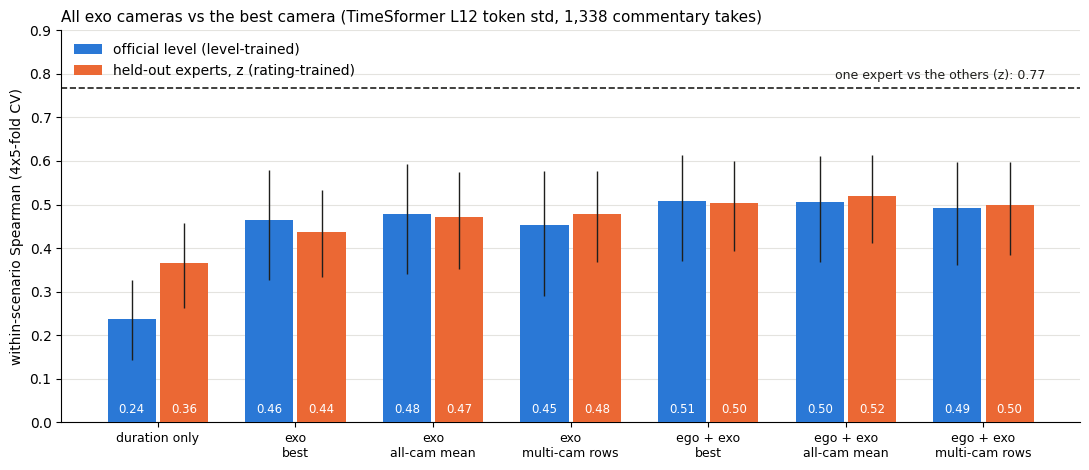

In [8]:
import matplotlib.pyplot as plt
show = ["duration only", "exo best", "exo all-cam mean", "exo multi-cam rows", "ego + exo best", "ego + exo all-cam mean", "ego + exo multi-cam rows"]
fig, ax = plt.subplots(figsize=(11, 4.8))
w = 0.38
for k, (col, target, label, color) in enumerate([("vs level", "level", "official level (level-trained)", "#2a78d6"),
                                                 ("vs experts z", "rating z", "held-out experts, z (rating-trained)", "#eb6834")]):
    xs = np.arange(len(show)) + (k - 0.5) * w
    vals = np.array([results[(m, target)][col][0] for m in show])
    lo = np.array([np.nanquantile(results[(m, target)][col][1], 0.025) for m in show])
    hi = np.array([np.nanquantile(results[(m, target)][col][1], 0.975) for m in show])
    ax.bar(xs, vals, w * 0.92, color=color, label=label, zorder=3)
    ax.errorbar(xs, vals, yerr=[vals - lo, hi - vals], fmt="none", ecolor="#1f1f1d", elinewidth=1, capsize=0, zorder=4)
    for x, v in zip(xs, vals):
        ax.text(x, 0.015, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5, color="white", zorder=5)
ax.axhline(sp(H.one_z_c, H.others_z_c), color="#1f1f1d", lw=1.2, ls="--", zorder=2)
ax.text(len(show) - 0.55, sp(H.one_z_c, H.others_z_c) + 0.015, f"one expert vs the others (z): {sp(H.one_z_c, H.others_z_c):.2f}",
        ha="right", va="bottom", fontsize=9, color="#1f1f1d")
ax.set_xticks(range(len(show)), [s.replace("ego + exo ", "ego + exo\n").replace("exo ", "exo\n", 1) if not s.startswith("ego") else s.replace("ego + exo ", "ego + exo\n") for s in show], fontsize=9)
ax.set_ylabel("within-scenario Spearman (4x5-fold CV)")
ax.set_ylim(0, 0.9)
ax.grid(axis="y", color="#e4e3df", zorder=0)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left")
ax.set_title("All exo cameras vs the best camera (TimeSformer L12 token std, 1,338 commentary takes)", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/multicam.png", dpi=150)
plt.show()